In [2]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib import ticker
from scipy.stats import kruskal
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

from mol_faith.notebooks.results_analysis.shared import get_target_colors
from mol_faith.notebooks.results_analysis.shared import map_explanation_method_names
from mol_faith.notebooks.results_analysis.shared import load_raw_data
from mol_faith.notebooks.results_analysis.shared import get_model_colors
from mol_faith.notebooks.results_analysis.shared import process_fidelity_df
from mol_faith.notebooks.results_analysis.shared import load_raw_data_all_thres, process_fidelity_df_all_thres

In [3]:
benzene_target_base_path = '../../../results/benzene_target'
benzene_raw_data_df = load_raw_data(base_dir=benzene_target_base_path, target_name='benzene')

conjugated_system_target_base_path = '../../../results/conjugated_system_target'
conjugated_system_raw_data_df = load_raw_data(base_dir=conjugated_system_target_base_path, target_name='conjugated_system')

hbond_donor_target_base_path = '../../../results/hbond_donor'
hbond_donor_raw_data_df = load_raw_data(base_dir=hbond_donor_target_base_path, target_name='hbond_donor')

Found XAI methods: ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling']
Excluded methods: []

Processing GCN...
  gnn_explainer: 6900 rows
  grad_cam: 6900 rows
  graph_mask: 6900 rows
  guided_grad_cam: 5677 rows
  integrated_gradients: 6900 rows
  kernel_shap: 6900 rows
  lime: 6900 rows
  random_explanation: 6900 rows
  shap_sampling: 6900 rows
  GCN total: 60877 rows

Processing Transformer...
  integrated_gradients: 6900 rows
  kernel_shap: 6900 rows
  lime: 6900 rows
  random_explanation: 6900 rows
  shap_sampling: 6900 rows
  Transformer total: 34500 rows

Processing CNN...
  grad_cam: 6900 rows
  guided_grad_cam: 4258 rows
  integrated_gradients: 6900 rows
  kernel_shap: 6900 rows
  lime: 6900 rows
  random_explanation: 6900 rows
  shap_sampling: 6900 rows
  CNN total: 45658 rows

Processing GIN...
  gnn_explainer: 6900 rows
  graph_mask: 6900 rows
  integrated_gradients: 6900 rows
 

# Random Baseline Comparison

In [4]:
conjugated_system_raw_data_df[
	(conjugated_system_raw_data_df['model'] == 'GAT') &
	(conjugated_system_raw_data_df['explanation_method'] == 'random_explanation')
].describe()


,data_split_idx,target,fid_plus
count,6900.000000,6900.000000,6900.000000
mean,2.000000,0.284230,0.002322
std,1.414316,0.135795,0.008409
min,0.000000,0.000000,-0.034314
25%,1.000000,0.187500,-0.001259
50%,2.000000,0.281250,0.001001
75%,3.000000,0.375000,0.004234
max,4.000000,1.000000,0.136403


In [5]:
conjugated_system_raw_data_df[
    (conjugated_system_raw_data_df['model'] == 'GIN') &
	(conjugated_system_raw_data_df['explanation_method'] == 'random_explanation')
    ].describe()


,data_split_idx,target,fid_plus
count,6900.000000,6900.000000,6900.000000
mean,2.000000,0.284230,0.000775
std,1.414316,0.135795,0.003872
min,0.000000,0.000000,-0.024456
25%,1.000000,0.187500,-0.000401
50%,2.000000,0.281250,0.000125
75%,3.000000,0.375000,0.001340
max,4.000000,1.000000,0.086362


In [6]:
conjugated_system_raw_data_df[
    (conjugated_system_raw_data_df['model'] == 'GCN') &
	(conjugated_system_raw_data_df['explanation_method'] == 'random_explanation')
    ].describe()


,data_split_idx,target,fid_plus
count,6900.000000,6900.000000,6900.000000
mean,2.000000,0.284230,0.001153
std,1.414316,0.135795,0.008054
min,0.000000,0.000000,-0.146457
25%,1.000000,0.187500,-0.001056
50%,2.000000,0.281250,0.000715
75%,3.000000,0.375000,0.003478
max,4.000000,1.000000,0.089929


In [7]:
conjugated_system_raw_data_df[
    (conjugated_system_raw_data_df['model'] == 'CNN') &
	(conjugated_system_raw_data_df['explanation_method'] == 'random_explanation')
    ].describe()


,data_split_idx,target,fid_plus
count,6900.000000,6900.000000,6900.000000
mean,2.000000,0.284230,0.004152
std,1.414316,0.135795,0.012383
min,0.000000,0.000000,-0.048767
25%,1.000000,0.187500,-0.002209
50%,2.000000,0.281250,0.003075
75%,3.000000,0.375000,0.008986
max,4.000000,1.000000,0.105893


In [8]:
conjugated_system_raw_data_df[
    (conjugated_system_raw_data_df['model'] == 'Transformer') &
	(conjugated_system_raw_data_df['explanation_method'] == 'random_explanation')
    ].describe()


,data_split_idx,target,fid_plus
count,6900.000000,6900.000000,6900.000000
mean,2.000000,0.284230,0.004400
std,1.414316,0.135795,0.018804
min,0.000000,0.000000,-0.098599
25%,1.000000,0.187500,-0.004543
50%,2.000000,0.281250,0.002305
75%,3.000000,0.375000,0.010871
max,4.000000,1.000000,0.220785


# Normalize Scores

In [9]:
benzene_raw_processed_data_df = process_fidelity_df(benzene_raw_data_df)
conjugated_system_raw_processed_data_df = process_fidelity_df(conjugated_system_raw_data_df)
hbond_donor_raw_processed_data_df = process_fidelity_df(hbond_donor_raw_data_df)

Total samples: 203135

Regime distribution:
regime
faithful      149075
unfaithful     54060
Name: count, dtype: int64

Faithfulness statistics by regime:
           normalized_fid                                   fid_plus          \
                    count    mean  median     std  min  max     mean     min   
regime                                                                         
faithful           149075  0.5088  0.7199  0.5454 -1.0  1.0   0.0183  0.0000   
unfaithful          54060 -0.5758 -0.5593  0.3706 -1.0 -0.0  -0.0036 -0.2565   

                    
               max  
regime              
faithful    0.3804  
unfaithful -0.0000  

Overall faithfulness score range: [-1.000, 1.000]
Total samples: 205971

Regime distribution:
regime
faithful      154068
unfaithful     51903
Name: count, dtype: int64

Faithfulness statistics by regime:
           normalized_fid                                   fid_plus          \
                    count    mean  median     std  mi

# Model Comparison

In [10]:
def kruskal_by_model_target(df_dict, value_col='normalized_fid'):
    df_list = []
    for target_name, df in df_dict.items():
        df_temp = df.copy()
        df_temp['target'] = target_name
        df_list.append(df_temp)

    df_combined = pd.concat(df_list, ignore_index=True)
    df_combined = df_combined[np.isfinite(df_combined[value_col])].copy()

    df_combined['model_target'] = df_combined['model'] + '_' + df_combined['target']

    grouped = df_combined.groupby('model_target')[value_col]
    groups = [vals.values for _, vals in grouped]
    group_names = grouped.groups.keys()
    k = len(groups)
    N = len(df_combined)

    H, p = kruskal(*groups)

    # Compute effect sizes
    eta_sq = (H - k + 1) / (N - k)

    results_df = pd.DataFrame({
        'test_name': ['Kruskal–Wallis'],
        'H_statistic': [H],
        'p_value': [p],
        'n_groups': [k],
        'N': [N],
        'eta_squared_H': [eta_sq],
        'groups': [list(group_names)]
    })

    return results_df

In [11]:
df_dict = {
    'benzene': benzene_raw_processed_data_df,
    'conjugated_system': conjugated_system_raw_processed_data_df,
    'hbond_donor': hbond_donor_raw_processed_data_df
}

kruskal_wallis_model_results = kruskal_by_model_target(df_dict)
kruskal_wallis_model_results

,test_name,H_statistic,p_value,n_groups,N,eta_squared_H,groups
0,Kruskal–Wallis,12196.291554,0.0,15,613741,0.01985,"[CNN_benzene, CNN_conjugated_system, CNN_hbond..."


# Method Comparison

In [12]:
def kruskal_by_method_target(df_dict, value_col='normalized_fid'):
    df_list = []
    for target_name, df in df_dict.items():
        df_temp = df.copy()
        df_temp['target'] = target_name
        df_list.append(df_temp)

    df_combined = pd.concat(df_list, ignore_index=True)
    df_combined = df_combined[np.isfinite(df_combined[value_col])].copy()

    # Create combined explanation_method_target identifier
    df_combined['method_target'] = df_combined['explanation_method'] + '_' + df_combined['target']

    grouped = df_combined.groupby('method_target')[value_col]
    groups = [vals.values for _, vals in grouped]
    group_names = grouped.groups.keys()
    k = len(groups)
    N = len(df_combined)

    H, p = kruskal(*groups)

    # Compute effect sizes
    eta_sq = (H - k + 1) / (N - k)

    results_df = pd.DataFrame({
        'test_name': ['Kruskal–Wallis'],
        'H_statistic': [H],
        'p_value': [p],
        'n_groups': [k],
        'N': [N],
        'eta_squared': [eta_sq],
        'groups': [list(group_names)]
    })

    return results_df

In [13]:
df_dict = {
    'benzene': benzene_raw_processed_data_df,
    'conjugated_system': conjugated_system_raw_processed_data_df,
    'hbond_donor': hbond_donor_raw_processed_data_df
}

kruskal_wallis_method_results = kruskal_by_method_target(df_dict)
kruskal_wallis_method_results

,test_name,H_statistic,p_value,n_groups,N,eta_squared,groups
0,Kruskal–Wallis,75152.668868,0.0,24,613741,0.122417,"[gnn_explainer_benzene, gnn_explainer_conjugat..."


# Target Comparison

In [14]:
def kruskal_by_target(df_dict, value_col='normalized_fid'):
    df_list = []
    for target_name, df in df_dict.items():
        df_temp = df.copy()
        df_temp['target'] = target_name
        df_list.append(df_temp)

    df_combined = pd.concat(df_list, ignore_index=True)
    df_combined = df_combined[np.isfinite(df_combined[value_col])].copy()

    grouped = df_combined.groupby('target')[value_col]
    groups = [vals.values for _, vals in grouped]
    group_names = list(grouped.groups.keys())
    k = len(groups)
    N = len(df_combined)

    H, p = kruskal(*groups)

    # Calculate effect size (Eta-squared)
    eta_sq = (H - k + 1) / (N - k)


    results_df = pd.DataFrame({
        'test_name': ['Kruskal–Wallis (by Target)'],
        'H_statistic': [H],
        'p_value': [p],
        'n_groups': [k],
        'N': [N],
        'eta_squared': [eta_sq],
        'groups': [group_names]
    })

    return results_df

In [15]:
df_dict = {
    'benzene': benzene_raw_processed_data_df,
    'conjugated_system': conjugated_system_raw_processed_data_df,
    'hbond_donor': hbond_donor_raw_processed_data_df
}

kruskal_wallis_target_results = kruskal_by_target(df_dict)
kruskal_wallis_target_results

,test_name,H_statistic,p_value,n_groups,N,eta_squared,groups
0,Kruskal–Wallis (by Target),6125.640348,0.0,3,613741,0.009978,"[benzene, conjugated_system, hbond_donor]"


# PCA

In [16]:
def aggregate_and_merge_normalized_fid(target_dfs):
    if not target_dfs:
        return pd.DataFrame()

    target_names = list(target_dfs.keys())  # preserve input order
    merged_df = None

    for target_name, df in target_dfs.items():
        grouped = (
            df.groupby(["model", "explanation_method"])["normalized_fid"]
              .median()
              .reset_index()
              .rename(columns={"normalized_fid": f"fid_normalized_median_{target_name}"})
        )

        # Merge across targets
        if merged_df is None:
            merged_df = grouped
        else:
            merged_df = pd.merge(
                merged_df,
                grouped,
                on=["model", "explanation_method"],
                how="outer"
            )

    fid_cols_in_order = [
        f"fid_normalized_median_{t}"
        for t in target_names
        if f"fid_normalized_median_{t}" in merged_df.columns
    ]
    merged_df = merged_df[["model", "explanation_method"] + fid_cols_in_order]

    min_row = {
        "model": "MIN",
        "explanation_method": "MIN",
        **{c: merged_df[c].min() for c in fid_cols_in_order},
    }
    max_row = {
        "model": "MAX",
        "explanation_method": "MAX",
        **{c: merged_df[c].max() for c in fid_cols_in_order},
    }

    merged_df = pd.concat([merged_df, pd.DataFrame([min_row, max_row])], ignore_index=True)

    return merged_df

In [17]:
target_dfs = {
    'benzene': benzene_raw_processed_data_df,
    'conjugated_system': conjugated_system_raw_processed_data_df,
    'hbond_donor': hbond_donor_raw_processed_data_df
}
merged_df = aggregate_and_merge_normalized_fid(target_dfs)

In [18]:
def perform_pca(df_with_minmax, sep="+"):
    df_clean = df_with_minmax.copy()

    fid_columns = [col for col in df_clean.columns if col.startswith("fid_")]
    if len(fid_columns) < 2:
        print(f"Error: Need at least 2 Fid columns, found {len(fid_columns)}")
        return None, None, None, None, None

    print(f"Using Fid columns for PCA: {fid_columns}")
    print(f"Found models: {[m for m in df_clean['model'].unique() if m not in ['MIN', 'MAX']]}")
    print(f"Found methods: {[m for m in df_clean['explanation_method'].unique() if m not in ['MIN', 'MAX']]}")

    fid_data = df_clean[fid_columns].values

    if np.any(np.isnan(fid_data)):
        valid_rows = ~np.any(np.isnan(fid_data), axis=1)
        fid_data = fid_data[valid_rows]
        df_clean = df_clean[valid_rows].copy()

    scaler = StandardScaler()
    fid_data_scaled = scaler.fit_transform(fid_data)

    pca = PCA(n_components=2)
    pca_result = pca.fit_transform(fid_data_scaled)

    pca_df = df_clean[["model", "explanation_method"]].copy()
    pca_df["PC1"] = pca_result[:, 0]
    pca_df["PC2"] = pca_result[:, 1]

    # Loadings (contribution of each fid column to each PC)
    loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

    print("\n✅ PCA complete.")
    print(f"Explained variance ratio: {pca.explained_variance_ratio_}")

    return pca_df, pca, scaler, loadings, fid_columns

In [19]:
pca_df, pca, scaler, loadings, fid_columns = perform_pca(merged_df)

Using Fid columns for PCA: ['fid_normalized_median_benzene', 'fid_normalized_median_conjugated_system', 'fid_normalized_median_hbond_donor']
Found models: ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer']
Found methods: ['grad_cam', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'shap_sampling', 'gnn_explainer', 'graph_mask']

✅ PCA complete.
Explained variance ratio: [0.88726589 0.06003569]


In [20]:
def plot_pca(pca_df, pca, loadings, fid_columns,
             show_loadings=False,
             figsize=(14, 10),
             font_scale=1,
             plot_linewidth=0.5,
             labelsize=9,
             tick_label_size=8,
             tick_width=0.5,
             tick_length=2,
             point_size=12,
             save_path=None):
   
    sns.set_style("whitegrid", {
        "axes.grid": False,
        'xtick.bottom': True,
        'ytick.left': True,
        'font': 'Arial'
    })
    sns.set_context("paper", font_scale=font_scale)

    model_colors = get_model_colors()

    fig, ax = plt.subplots(figsize=figsize)

    regular_points = pca_df[~pca_df['model'].isin(['MIN', 'MAX'])]
    minmax_points = pca_df[pca_df['model'].isin(['MIN', 'MAX'])]

    if len(regular_points) > 0:
        sns.scatterplot(data=regular_points, x='PC1', y='PC2', hue='model',  edgecolor='black',
                        palette=model_colors, s=point_size, alpha=1, linewidth=0.3, ax=ax)

    for idx, row in minmax_points.iterrows():
        ax.scatter(row['PC1'], row['PC2'], c='black', marker='o', s=point_size,  edgecolor='black',
                   alpha=1.0, linewidth=0.3, zorder=3)

    # Add labels for each point
    if len(minmax_points) > 0:
        min_point = pca_df[pca_df['model'] == 'MIN'].iloc[0]
    else:
        min_point = None

    crowded_offsets = [
        (50, 30), (50, -10), (30, 50), (70, 10),
        (30, -30), (50, -30), (10, 60), (80, -10)
    ]
    crowded_counter = 0

    for idx, row in pca_df.iterrows():
        if row['model'] in ['MIN', 'MAX']:
            label_text = row['model']
            offset = (8, 8)
            use_connection = False
        else:
            label_text = row['explanation_method']
            if min_point is not None:
                distance_from_min = ((row['PC1'] - min_point['PC1']) ** 2 + (row['PC2'] - min_point['PC2']) ** 2) ** 0.5

                if distance_from_min < 0.8:
                    offset = crowded_offsets[crowded_counter % len(crowded_offsets)]
                    crowded_counter += 1
                    use_connection = True
                else:
                    offset = (5, 5)
                    use_connection = False
            else:
                offset = (5, 5)
                use_connection = False

        # if use_connection:
        #     ax.annotate(label_text,
        #                 xy=(row['PC1'], row['PC2']),
        #                 xytext=offset,
        #                 textcoords='offset points',
        #                 fontsize=labelsize,
        #                 alpha=0.9,
        #                 arrowprops=dict(arrowstyle='->', color='black', lw=1.2, alpha=0.8,
        #                                 connectionstyle="arc3,rad=0.1"))
        # else:
        #     ax.annotate(label_text,
        #                 xy=(row['PC1'], row['PC2']),
        #                 xytext=offset,
        #                 textcoords='offset points',
        #                 fontsize=labelsize,
        #                 alpha=0.9)

    # Draw line between MIN and MAX
    if len(minmax_points) >= 2:
        min_point = pca_df[pca_df['model'] == 'MIN'].iloc[0]
        max_point = pca_df[pca_df['model'] == 'MAX'].iloc[0]
        ax.plot([min_point['PC1'], max_point['PC1']],
                [min_point['PC2'], max_point['PC2']],
                'k--', linewidth=plot_linewidth, alpha=0.7)

    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.3f} explained variance)', fontsize=labelsize)
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.3f} explained variance)', fontsize=labelsize)
    ax.set_aspect('equal', adjustable='box')
    ax.tick_params(axis='both', labelsize=tick_label_size, width=tick_width, length=tick_length)

    for spine in ax.spines.values():
        spine.set_linewidth(plot_linewidth)

    if ax.get_legend() is not None:
        ax.get_legend().remove()

    ax.axhline(y=0, color='lightgray', linestyle='-', linewidth=plot_linewidth, alpha=0.7, zorder=0)
    ax.axvline(x=0, color='lightgray', linestyle='-', linewidth=plot_linewidth, alpha=0.7, zorder=0)

    if show_loadings:
        scale_factor = max(ax.get_xlim()[1] - ax.get_xlim()[0],
                           ax.get_ylim()[1] - ax.get_ylim()[0]) / 3

        for i, fid_col in enumerate(fid_columns):
            target_name = fid_col.replace('Fid_', '').replace('_target', '')

            ax.arrow(0, 0,
                     loadings[i, 0] * scale_factor,
                     loadings[i, 1] * scale_factor,
                     head_width=scale_factor * 0.05,
                     head_length=scale_factor * 0.08,
                     fc='black', ec='black', alpha=0.8, linewidth=plot_linewidth)

            ax.text(loadings[i, 0] * scale_factor * 1.15,
                    loadings[i, 1] * scale_factor * 1.15,
                    target_name,
                    fontsize=6, ha='center', va='center')

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, format='svg', dpi=450, bbox_inches='tight', facecolor='white')

    plt.show()
    return fig, ax

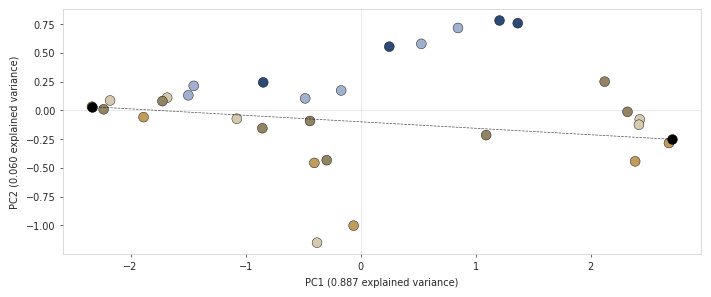

(<Figure size 720x400 with 1 Axes>,
 <Axes: xlabel='PC1 (0.887 explained variance)', ylabel='PC2 (0.060 explained variance)'>)

In [22]:
plot_pca(pca_df, pca, loadings, fid_columns,
         save_path='./pca_plot_loadings.svg',
         figsize=(7.2, 4),
         point_size=50,
         font_scale=1,
         plot_linewidth=0.5,
         labelsize=7,
         tick_label_size=7,
         tick_width=0.5,
         tick_length=2,
         show_loadings=False
         )


# Box Plots

In [23]:
def create_grouped_boxplot(target_dataframes,
                           value_col,
                           group_col,
                           figsize=(7, 3),
                           save_plot=False,
                           output_dir=None,
                           linewidth=2,
                           box_width=0.18,
                           gap=0.1,
                           font_scale=1,
                           show_minmax=True,
                           minmax_marker='D',
                           minmax_size=30,
                           plot_linewidth=0.5,
                           labelsize=9,
                           tick_label_size=8,
                           tick_width=0.5,
                           tick_length=2,
                           reference_fig=None):
    if not target_dataframes:
        print("No data provided!")
        return None

    combined_data = []
    for target, df in target_dataframes.items():
        if df.empty:
            continue
        df_copy = df.copy()
        df_copy['target'] = target
        df_copy = map_explanation_method_names(df_copy)
        combined_data.append(df_copy)

    if not combined_data:
        print("No valid data found!")
        return None

    full_df = pd.concat(combined_data, ignore_index=True)

    if group_col == 'model':
        label_order = ['Transformer', 'CNN', 'GAT', 'GCN', 'GIN']
    else:
        label_order = ['IG', 'SHAP', 'KernelSHAP', 'LIME', 'GradCAM', 'Guided GradCAM', 'GNNExplainer', 'GraphMask']

    targets = list(target_dataframes.keys())

    print(f"Creating seaborn grouped boxplot with {len(label_order)} groups and {len(targets)} targets per group")

    fig, ax = plt.subplots(figsize=figsize)

    sns.set_style("whitegrid", {"axes.grid": False, 'xtick.bottom': True, 'ytick.left': True, 'font': 'Arial'})
    sns.set_context("paper")

    target_colors = get_target_colors()

    box_plot = sns.boxplot(
        data=full_df,
        x=group_col,
        y=value_col,
        hue='target',
        hue_order=['Conjugated System', 'Benzene', 'Hbond Donor'],
        order=label_order,
        linewidth=linewidth,
        ax=ax,
        palette=target_colors,
        width=box_width,
        showfliers=False,
        gap=gap,
        dodge=True,
        legend=False
    )

    ax.axhline(y=0, color='grey', linestyle='-', linewidth=plot_linewidth, alpha=0.5, zorder=1)

    if show_minmax:
        minmax_data = []

        for method in label_order:
            method_data = full_df[full_df[group_col] == method]
            for target in targets:
                target_data = method_data[method_data['target'] == target][value_col].dropna()
                if len(target_data) > 0:
                    min_val = target_data.min()
                    max_val = target_data.max()

                    minmax_data.append({
                        group_col: method,
                        'target': target,
                        'min_val': min_val,
                        'max_val': max_val
                    })

        minmax_df = pd.DataFrame(minmax_data)


        method_positions = list(range(len(label_order)))
        n_targets = len(targets)

        if n_targets > 1:
            group_width = 0.8 / n_targets
            offsets = np.linspace(-0.461 + group_width / 2, 0.461 - group_width / 2, n_targets)
        else:
            offsets = [0]

        for _, row in minmax_df.iterrows():
            method_idx = label_order.index(row[group_col])
            target_idx = targets.index(row['target'])
            x_pos = method_idx + offsets[target_idx] * (1 - gap)

            color = target_colors[row['target']]

            ax.scatter(x_pos, row['min_val'],
                       marker=minmax_marker,
                       s=minmax_size,
                       color=color,
                       edgecolor='black',
                       linewidth=1,
                       alpha=0.8,
                       zorder=10)

            ax.scatter(x_pos, row['max_val'],
                       marker=minmax_marker,
                       s=minmax_size,
                       color=color,
                       edgecolor='black',
                       linewidth=1,
                       alpha=0.8,
                       zorder=10)

    x_label = 'Model' if group_col == 'model' else 'xAI Method'
    ax.set_xlabel(x_label, fontsize=labelsize)
    ax.set_ylabel('Fid+', fontsize=labelsize)
    ax.tick_params(axis='y', labelsize=tick_label_size, width=tick_width, length=tick_length)
    ax.tick_params(axis='x', labelsize=tick_label_size, width=tick_width, length=tick_length)
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))

    if group_col != 'model':
        if reference_fig is not None:
            ref_ax = reference_fig.get_axes()[0]
            ref_yticks = ref_ax.get_yticks()
            ref_ylim = ref_ax.get_ylim()
            visible_ticks = [tick for tick in ref_yticks if ref_ylim[0] <= tick <= ref_ylim[1]]
            ax.set_yticks(visible_ticks)
            ax.set_ylim(ref_ylim) 
        else:
            ax.set_yticks([0.12, 0.08, 0.05, 0.02, 0.00, -0.02, -0.05, -0.08])

    for spine in ax.spines.values():
        spine.set_linewidth(plot_linewidth)

    handles, labels = ax.get_legend_handles_labels()

    if show_minmax:
        minmax_handle = Line2D([0], [0],
                               marker=minmax_marker,
                               color='gray',
                               markerfacecolor='gray',
                               markeredgecolor='black',
                               markersize=8,
                               linewidth=0,
                               alpha=0.8)
        handles.append(minmax_handle)
        labels.append('Min/Max')

    # Move legend outside plot area with updated handles and labels
    # ax.legend(handles=handles, labels=labels,
    #           loc='center left', bbox_to_anchor=(1, 0.5), fontsize=11,
    #           title='Target')

    plt.tight_layout()

    if group_col == 'model':
        saving_prefix = 'model'
    else:
        saving_prefix = 'method'

    if save_plot and output_dir:
        Path(output_dir).mkdir(parents=True, exist_ok=True)
        plt.savefig(Path(output_dir) / f'{saving_prefix}_grouped_boxplot.png', dpi=450, bbox_inches='tight')
        plt.savefig(Path(output_dir) / f'{saving_prefix}_grouped_boxplot.svg', format='svg', dpi=450,
                    bbox_inches='tight')

    plt.show()
    return fig

In [24]:
target_data = {
    'Benzene': benzene_raw_processed_data_df,
    'Conjugated System': conjugated_system_raw_processed_data_df,
    'Hbond Donor': hbond_donor_raw_processed_data_df
}

Creating seaborn grouped boxplot with 5 groups and 3 targets per group


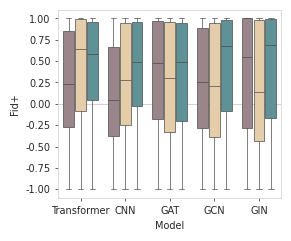

In [27]:
model_fig = create_grouped_boxplot(target_data,
                       value_col='normalized_fid',
                       group_col='model',
                       figsize=(3, 2.5),
                       save_plot=True,
                       box_width=0.8,
                       gap=0.09,
                       linewidth=0.5,
                       plot_linewidth=0.5,
                       show_minmax=False,
                       labelsize=7,
                       tick_label_size=7,
                       minmax_size=12,
                       output_dir='/home/marcelhiltscher/Documents/Projects/Faithfulness_Test/mol_faith/notebooks/analysis')

Creating seaborn grouped boxplot with 8 groups and 3 targets per group


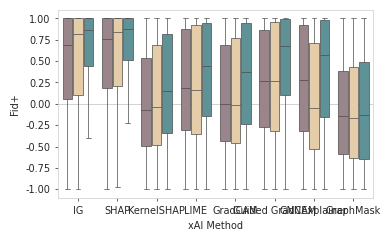

In [29]:
model_fig = create_grouped_boxplot(target_data,
                       value_col='normalized_fid',
                       group_col='explanation_method',
                       figsize=(4, 2.5),
                       save_plot=True,
                       box_width=0.8,
                       gap=0.09,
                       linewidth=0.5,
                       plot_linewidth=0.5,
                       labelsize=7,
                       tick_label_size=7,
                       show_minmax=False,
                       minmax_size=12,
                       output_dir='/home/marcelhiltscher/Documents/Projects/Faithfulness_Test/mol_faith/notebooks/analysis',
                       reference_fig=model_fig)

# Summary Table

In [30]:
def combine_and_calculate_variance(target_dataframes, map_explanation_method_names):
    combined_data = []
    for target, df in target_dataframes.items():
        if df.empty:
            continue
        df_copy = df.copy()
        df_copy["target"] = target
        df_copy = map_explanation_method_names(df_copy)
        combined_data.append(df_copy)

    if not combined_data:
        print("⚠️ No data available for variance calculation.")
        return pd.DataFrame()

    combined_df = pd.concat(combined_data, ignore_index=True)

    required_cols = {"model", "explanation_method", "normalized_fid", "target"}
    missing = required_cols - set(combined_df.columns)
    if missing:
        raise ValueError(f"Missing columns for variance calculation: {missing}")

    summary_df = (
        combined_df.groupby(["model", "explanation_method", "target"])
        .agg(
            n=("normalized_fid", "count"),
            mean=("normalized_fid", "mean"),
            median=("normalized_fid", "median"),
            std=("normalized_fid", "std"),
            var=("normalized_fid", "var"),
        )
        .reset_index()
        .sort_values(["target", "model", "explanation_method"])
    )

    numeric_cols = ["mean", "median", "std", "var"]
    summary_df[numeric_cols] = summary_df[numeric_cols].round(3)
    summary_df.sort_values(by=["median"], inplace=True, ascending=False)

    print(f"✅ Combined dataframe: {len(combined_df):,} rows from {len(target_dataframes)} targets")
    print(f"✅ Summary table: {len(summary_df):,} model–method–target combinations")

    return summary_df

In [31]:
variance_analysis = combine_and_calculate_variance(target_data, map_explanation_method_names)

✅ Combined dataframe: 613,741 rows from 3 targets
✅ Summary table: 90 model–method–target combinations


In [65]:
variance_analysis.to_latex(
    "/home/marcelhiltscher/Documents/Projects/Faithfulness_Test/mol_faith/notebooks/analysis/supplementary_fid_variance_table.tex",
    index=False,
    float_format="%.3f",
    column_format="lllrllll",
    caption=(
        "Summary of normalized F-Fid$^+$ statistics across all model--method--target "
        "combinations. The table reports mean, median, standard deviation, and variance "
        "of normalized F-Fid$^+$ values across molecules for each configuration. "
        "High standard deviation values indicate large input-dependent variation "
        "in faithfulness scores within the same model and explanation method."
    ),
    label="tab:supp_fid_variation",
    escape=False)

In [32]:
variance_analysis['std'].median()

0.651

# Standard Deviation Plot

In [33]:
def plot_std_by_method_target(variance_df, 
                               figsize=(3, 2.5),
                               save_plot=False,
                               output_dir=None,
                               plot_linewidth=0.5,
                               labelsize=7,
                               tick_label_size=7,
                               tick_width=0.5,
                               tick_length=2,
                               point_size=5,
                               alpha=0.7):
    targets = variance_df['target'].unique()
    
    model_colors = get_model_colors()
    
    # Map explanation method names
    # variance_df = map_explanation_method_names(variance_df)
    
    method_order = ['IG', 'SHAP', 'KernelSHAP', 'LIME', 'GradCAM', 
                    'Guided GradCAM', 'GNNExplainer', 'GraphMask']
    
    sns.set_style("whitegrid", {
        "axes.grid": False, 
        'xtick.bottom': True, 
        'ytick.left': True, 
        'font': 'Arial'
    })
    sns.set_context("paper")
    
    figures = {}
    
    for target in targets:
        df_target = variance_df[variance_df['target'] == target].copy()
        
        fig, ax = plt.subplots(figsize=figsize)

        sns.stripplot(
            data=df_target,
            x='explanation_method',
            y='std',
            hue='model',
            palette=model_colors,
            order=method_order,
            dodge=False,
            jitter=False,
            alpha=alpha,
            linewidth=plot_linewidth,
            size=point_size,
            ax=ax,
            legend=False
        )
        
        ax.set_xlabel('xAI Method', fontsize=labelsize)
        ax.set_ylabel('Standard Deviation (Fid⁺)', fontsize=labelsize)
        ax.tick_params(axis='y', labelsize=tick_label_size, width=tick_width, length=tick_length)
        ax.tick_params(axis='x', labelsize=tick_label_size, width=tick_width, length=tick_length, rotation=45)
        ax.set_xticklabels([])

        for spine in ax.spines.values():
            spine.set_linewidth(plot_linewidth)

        ax.axhline(y=0, color='grey', linestyle='-', 
                  linewidth=plot_linewidth, alpha=0.5, zorder=1)

        ax.axhline(y=df_target['std'].median(), color='black', linestyle='dashed', 
                  linewidth=plot_linewidth, alpha=0.5, zorder=1)
        
        plt.tight_layout()
        
        if save_plot and output_dir:
            Path(output_dir).mkdir(parents=True, exist_ok=True)
            safe_target = target.replace(' ', '_').lower()
            plt.savefig(Path(output_dir) / f'std_by_method_{safe_target}.png', 
                       dpi=450, bbox_inches='tight')
            plt.savefig(Path(output_dir) / f'std_by_method_{safe_target}.svg', 
                       format='svg', dpi=450, bbox_inches='tight')
        
        plt.show()
        figures[target] = fig
    
    return figures

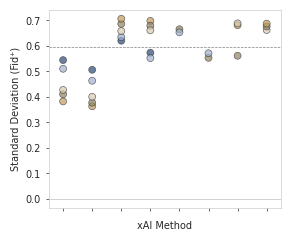

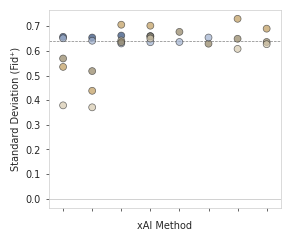

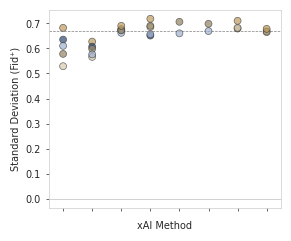

{'Hbond Donor': <Figure size 300x250 with 1 Axes>,
 'Conjugated System': <Figure size 300x250 with 1 Axes>,
 'Benzene': <Figure size 300x250 with 1 Axes>}

In [35]:
plot_std_by_method_target(variance_analysis, save_plot=False, output_dir='./')

In [36]:
def calculate_stats_by_method_target(target_dataframes, map_explanation_method_names=None, value_col='normalized_fid'):
    combined_data = []
    for target, df in target_dataframes.items():
        if df.empty:
            continue
        df_copy = df.copy()
        df_copy["target"] = target
        
        if map_explanation_method_names:
            df_copy = map_explanation_method_names(df_copy)
            
        combined_data.append(df_copy)

    if not combined_data:
        print("⚠️ No data available for stats calculation.")
        return pd.DataFrame()

    combined_df = pd.concat(combined_data, ignore_index=True)
    
    combined_df = combined_df[np.isfinite(combined_df[value_col])].copy()

    required_cols = {"explanation_method", value_col, "target"}
    missing = required_cols - set(combined_df.columns)
    if missing:
        raise ValueError(f"Missing columns for calculation: {missing}")

    summary_df = (
        combined_df.groupby(["explanation_method", "target"])
        .agg(
            n=(value_col, "count"),
            median=(value_col, "median"),
            std=(value_col, "std"),
            var=(value_col, "var"),
        )
        .reset_index()
        .sort_values(["target", "explanation_method"])
    )

    summary_df = (
        combined_df.groupby(["explanation_method"])
        .agg(
            n=(value_col, "count"),
            median=(value_col, "median"),
            std=(value_col, "std"),
            var=(value_col, "var"),
        )
        .reset_index()
        .sort_values(["explanation_method"])
    )

    return summary_df

In [37]:
calculate_stats_by_method_target(target_data, map_explanation_method_names)

,explanation_method,n,median,std,var
0,GNNExplainer,62099,0.256877,0.689718,0.475711
1,GradCAM,41400,0.111168,0.678668,0.460590
2,GraphMask,62100,-0.147141,0.666088,0.443673
3,Guided GradCAM,34142,0.427245,0.649373,0.421685
4,IG,103500,0.796982,0.574624,0.330193
5,KernelSHAP,103500,-0.015151,0.670311,0.449316
6,LIME,103500,0.268715,0.668050,0.446291
7,SHAP,103500,0.831934,0.548799,0.301180


# Fid target Correlation with input

In [38]:
def merge_target_dataframes_common_samples(target_dict):
    merge_keys = ['model', 'smiles', 'explanation_method']
    
    merged_df = None
    
    for target_name, df in target_dict.items():
        df_aggregated = df.groupby(merge_keys, as_index=False)['normalized_fid'].median()
        
        df_aggregated = df_aggregated.rename(columns={'normalized_fid': f'normalized_fid_{target_name}'})
        
        if merged_df is None:
            merged_df = df_aggregated
        else:
            merged_df = merged_df.merge(df_aggregated, on=merge_keys, how='inner')
    
    return merged_df

In [39]:
target_data = {
    'Benzene': benzene_raw_processed_data_df,
    'Conjugated System': conjugated_system_raw_processed_data_df,
    'Hbond Donor': hbond_donor_raw_processed_data_df
}
common_samples_merge = merge_target_dataframes_common_samples(target_data)

In [40]:
def analyze_target_correlations(merged_df, target_names):
    fid_cols = [f'normalized_fid_{target}' for target in target_names]
    
    correlation_kendall = merged_df[fid_cols].corr(method='spearman')
    
    return correlation_kendall

In [41]:
analyze_target_correlations(common_samples_merge, ['Benzene', 'Conjugated System', 'Hbond Donor'])

,normalized_fid_Benzene,normalized_fid_Conjugated System,normalized_fid_Hbond Donor
normalized_fid_Benzene,1.000000,0.118933,0.143065
normalized_fid_Conjugated System,0.118933,1.000000,0.155517
normalized_fid_Hbond Donor,0.143065,0.155517,1.000000


# OLS Analysis

In [42]:
target_data = {
    'Benzene': benzene_raw_processed_data_df,
    'Conjugated System': conjugated_system_raw_processed_data_df,
    'Hbond Donor': hbond_donor_raw_processed_data_df
}

In [43]:
def compute_effect_sizes(ols_model, type):
    anova_res = anova_lm(ols_model, typ=type)

    ss_resid = ols_model.ssr
    print(ss_resid)

    # Compute effect sizes
    anova_res["eta_sq"] = anova_res["sum_sq"] / (anova_res["sum_sq"].sum() + ss_resid)
    anova_res["eta_sq_partial"] = anova_res["sum_sq"] / (anova_res["sum_sq"] + ss_resid)

    print("===== Type II ANOVA (η² and partial η²) =====")
    print(anova_res[["sum_sq", "df", "F", "PR(>F)", "eta_sq", "eta_sq_partial"]])

    return anova_res

## OLS (shared methods)

In [44]:
def fit_shared_fid_ols(target_dataframes):
    combined_data = []
    for target, df in target_dataframes.items():
        if not df.empty:
            combined_data.append(df.copy())

    df_all = pd.concat(combined_data, ignore_index=True)
    print(f"✅ Combined dataset shape: {df_all.shape}")
    print(f"Targets: {df_all['target_name'].unique().tolist()}")

    shared_methods = ["integrated_gradients", "kernel_shap", "lime", "shap_sampling"]
    df_shared = df_all[df_all["explanation_method"].isin(shared_methods)].copy()

    # Ensure categorical encoding and set custom baselines
    # GIN baseline
    df_shared["model"] = pd.Categorical(
        df_shared["model"],
        categories=["GIN", "GAT", "GCN", "Transformer", "CNN"], 
        ordered=True,
    )

    # IG baseline
    df_shared["explanation_method"] = pd.Categorical(
        df_shared["explanation_method"],
        categories=["integrated_gradients", "shap_sampling", "lime", "kernel_shap"],
        ordered=True,
    )

    # H-bond donor baseline
    df_shared["target_name"] = pd.Categorical(
        df_shared["target_name"],
        categories=["hbond_donor", "conjugated_system", "benzene"],  
        ordered=True,
    )

    print(f"\n🧩 Fitting OLS model for shared XAI methods ...")
    print(f"Samples: {len(df_shared):,}")
    print(f"Models: {df_shared['model'].cat.categories.tolist()}")
    print(f"Methods: {df_shared['explanation_method'].cat.categories.tolist()}")
    print(f"Targets: {df_shared['target_name'].cat.categories.tolist()}\n")

    formula = "normalized_fid ~ model * explanation_method + target_name"
    ols_model = smf.ols(formula, data=df_shared).fit(cov_type="cluster", cov_kwds={"groups": df_shared["smiles"]})
    # ols_model = smf.ols(formula=formula, data=df_shared).fit(cov_type="HC3")

    print("\n===== OLS Regression Results (Shared Methods, GIN+IG+Hbond Baseline) =====")
    print(ols_model.summary())

    tidy = ols_model.summary2().tables[1].reset_index()
    tidy.columns = ["term", "coef", "std_err", "t", "p_value", "ci_low", "ci_high"]

    return df_shared, ols_model, tidy

In [45]:
df_shared, ols_model, ols_results = fit_shared_fid_ols(target_data)

✅ Combined dataset shape: (613741, 10)
Targets: ['benzene', 'conjugated_system', 'hbond_donor']

🧩 Fitting OLS model for shared XAI methods ...
Samples: 414,000
Models: ['GIN', 'GAT', 'GCN', 'Transformer', 'CNN']
Methods: ['integrated_gradients', 'shap_sampling', 'lime', 'kernel_shap']
Targets: ['hbond_donor', 'conjugated_system', 'benzene']


===== OLS Regression Results (Shared Methods, GIN+IG+Hbond Baseline) =====
                            OLS Regression Results                            
Dep. Variable:         normalized_fid   R-squared:                       0.142
Model:                            OLS   Adj. R-squared:                  0.141
Method:                 Least Squares   F-statistic:                     3193.
Date:                Mon, 29 Dec 2025   Prob (F-statistic):               0.00
Time:                        17:53:53   Log-Likelihood:            -3.8038e+05
No. Observations:              414000   AIC:                         7.608e+05
Df Residuals:             

In [46]:
df_effect_size = compute_effect_sizes(ols_model, type=2)
df_effect_size.to_latex("/home/marcelhiltscher/Documents/Projects/Faithfulness_Test/mol_faith/notebooks/analysis/supplementary_fid_effect_size_table.tex", float_format="%.4f")

152258.87163191644
===== Type II ANOVA (η² and partial η²) =====
                                 sum_sq        df             F  PR(>F)  \
model                        605.357408       4.0    411.477910     0.0   
explanation_method         16144.397801       3.0  14631.715580     0.0   
target_name                  596.024721       2.0    810.268457     0.0   
model:explanation_method    4439.458483      12.0   1005.873595     0.0   
Residual                  152258.871632  413978.0           NaN     NaN   

                            eta_sq  eta_sq_partial  
model                     0.001855        0.003960  
explanation_method        0.049477        0.095867  
target_name               0.001827        0.003899  
model:explanation_method  0.013605        0.028331  
Residual                  0.466618        0.500000  


In [47]:
df_effect_size = compute_effect_sizes(ols_model, type=3)

152258.87163191644
===== Type II ANOVA (η² and partial η²) =====
                                 sum_sq        df             F  PR(>F)  \
Intercept                   8745.756102       1.0  23778.914035     0.0   
model                       1719.349835       4.0   1168.688889     0.0   
explanation_method          7094.135980       3.0   6429.436466     0.0   
target_name                  596.024721       2.0    810.268457     0.0   
model:explanation_method    4439.458483      12.0   1005.873595     0.0   
Residual                  152258.871632  413978.0           NaN     NaN   

                            eta_sq  eta_sq_partial  
Intercept                 0.026736        0.054320  
model                     0.005256        0.011166  
explanation_method        0.021687        0.044518  
target_name               0.001822        0.003899  
model:explanation_method  0.013572        0.028331  
Residual                  0.465463        0.500000  


## OLS (graph only models)

In [48]:
def fit_graph_fid_ols(target_dataframes):
    combined_data = []
    for target, df in target_dataframes.items():
        if not df.empty:
            combined_data.append(df.copy())
    df_all = pd.concat(combined_data, ignore_index=True)
    print(f"✅ Combined dataset shape: {df_all.shape}")
    print(f"Targets: {df_all['target_name'].unique().tolist()}")

    graph_models = ["GIN", "GCN", "GAT"]
    df_graph = df_all[df_all["model"].isin(graph_models)].copy()

    excluded_methods = ["grad_cam", "guided_grad_cam"]
    df_graph = df_graph[~df_graph["explanation_method"].isin(excluded_methods)].copy()

    # Ensure categorical ordering (baseline first)
    # GIN baseline
    df_graph["model"] = pd.Categorical(df_graph["model"], categories=["GIN", "GCN", "GAT"], ordered=True)

    # IG baseline
    df_graph["explanation_method"] = pd.Categorical(
        df_graph["explanation_method"],
        categories=["integrated_gradients", "shap_sampling", "lime", "kernel_shap", "gnn_explainer", "graph_mask"],
        ordered=True
    )

    # H-bond donor baseline
    df_graph["target_name"] = pd.Categorical(
        df_graph["target_name"], 
        categories=["hbond_donor", "benzene", "conjugated_system"], 
        ordered=True
    )

    print(f"\n🧩 Fitting OLS for Graph Models ...")
    print(f"Samples: {len(df_graph):,}")
    print(f"Models: {df_graph['model'].unique().tolist()}")
    print(f"Methods: {df_graph['explanation_method'].unique().tolist()}\n")

    formula = "normalized_fid ~ model * explanation_method + target_name"
    # result_ols = smf.ols(formula, data=df_graph).fit(cov_type="HC3")
    result_ols = smf.ols(formula, data=df_graph).fit(cov_type="cluster", cov_kwds={"groups": df_graph["smiles"]})


    # 6️⃣ Output summary
    print("===== OLS Regression Results (Graph Models, GIN+IG+Hbond Baseline) =====")
    print(result_ols.summary())

    return df_graph, result_ols

In [44]:
df_shared_graph, ols_results_graph = fit_graph_fid_ols(target_data)

✅ Combined dataset shape: (613741, 10)
Targets: ['benzene', 'conjugated_system', 'hbond_donor']

🧩 Fitting OLS for Graph Models ...
Samples: 372,599
Models: ['GCN', 'GIN', 'GAT']
Methods: ['gnn_explainer', 'graph_mask', 'integrated_gradients', 'kernel_shap', 'lime', 'shap_sampling']

===== OLS Regression Results (Graph Models, GIN+IG+Hbond Baseline) =====
                            OLS Regression Results                            
Dep. Variable:         normalized_fid   R-squared:                       0.183
Model:                            OLS   Adj. R-squared:                  0.183
Method:                 Least Squares   F-statistic:                     4131.
Date:                Thu, 23 Oct 2025   Prob (F-statistic):               0.00
Time:                        15:47:08   Log-Likelihood:            -3.5294e+05
No. Observations:              372599   AIC:                         7.059e+05
Df Residuals:                  372579   BIC:                         7.061e+05
Df Model: 

In [45]:
ols_results_graph.summary().as_latex()

'\\begin{center}\n\\begin{tabular}{lclc}\n\\toprule\n\\textbf{Dep. Variable:}                                     & normalized\\_fid  & \\textbf{  R-squared:         } &      0.183   \\\\\n\\textbf{Model:}                                             &       OLS        & \\textbf{  Adj. R-squared:    } &      0.183   \\\\\n\\textbf{Method:}                                            &  Least Squares   & \\textbf{  F-statistic:       } &      4131.   \\\\\n\\textbf{Date:}                                              & Thu, 23 Oct 2025 & \\textbf{  Prob (F-statistic):} &      0.00    \\\\\n\\textbf{Time:}                                              &     15:47:22     & \\textbf{  Log-Likelihood:    } & -3.5294e+05  \\\\\n\\textbf{No. Observations:}                                  &      372599      & \\textbf{  AIC:               } &  7.059e+05   \\\\\n\\textbf{Df Residuals:}                                      &      372579      & \\textbf{  BIC:               } &  7.061e+05   \\\\\n\

In [49]:
df_effect_size = compute_effect_sizes(ols_results_graph)
df_effect_size.to_latex("/home/marcelhiltscher/Documents/Projects/Faithfulness_Test/mol_faith/notebooks/analysis/supplementary_fid_effect_size_table_graph.tex", float_format="%.4f")

145050.48158054415
===== Type II ANOVA (η² and partial η²) =====
                                 sum_sq        df             F  \
model                         76.812544       2.0     98.650969   
explanation_method         27113.773475       5.0  13928.974930   
target_name                  430.628598       2.0    553.059771   
model:explanation_method     384.153917      10.0     98.674393   
Residual                  145050.481581  372579.0           NaN   

                                 PR(>F)    eta_sq  eta_sq_partial  
model                      3.434703e-43  0.000241        0.000529  
explanation_method         0.000000e+00  0.085235        0.157488  
target_name               1.335805e-229  0.001354        0.002960  
model:explanation_method  1.109756e-196  0.001208        0.002641  
Residual                            NaN  0.455981        0.500000  


## OLS (conv only models)

In [ ]:
def fit_gradcam_fid_ols(target_dataframes):
    combined_data = []
    for target, df in target_dataframes.items():
        if not df.empty:
            combined_data.append(df.copy())
    df_all = pd.concat(combined_data, ignore_index=True)
    print(f"✅ Combined dataset shape: {df_all.shape}")
    print(f"Targets: {df_all['target_name'].unique().tolist()}")

    models_of_interest = ["CNN", "GCN"]
    df_subset = df_all[df_all["model"].isin(models_of_interest)].copy()

    methods_of_interest = [
        "integrated_gradients", "shap_sampling", "lime", "kernel_shap",
        "grad_cam", "guided_grad_cam"
    ]
    df_subset = df_subset[df_subset["explanation_method"].isin(methods_of_interest)].copy()

    # 4️⃣ Ensure consistent categorical ordering
    # GCN baseline
    df_subset["model"] = pd.Categorical(df_subset["model"], categories=["GCN", "CNN"], ordered=True)

    # IG baseline
    df_subset["explanation_method"] = pd.Categorical(
        df_subset["explanation_method"],
        categories=[
            "integrated_gradients", "shap_sampling", "lime", "kernel_shap",
            "grad_cam", "guided_grad_cam"
        ],
        ordered=True
    )

    # H-bond donor baseline
    df_subset["target_name"] = pd.Categorical(
        df_subset["target_name"],
        categories=["hbond_donor", "benzene", "conjugated_system"],
        ordered=True
    )

    print(f"\n🧩 Fitting OLS for GCN + CNN (shared + GradCAM methods) ...")
    print(f"Samples: {len(df_subset):,}")
    print(f"Models: {df_subset['model'].unique().tolist()}")
    print(f"Methods: {df_subset['explanation_method'].unique().tolist()}\n")

    formula = "normalized_fid ~ model * explanation_method + target_name"
    # result_ols = smf.ols(formula, data=df_subset).fit(cov_type="HC3")
    result_ols = smf.ols(formula, data=df_subset).fit(cov_type="cluster", cov_kwds={"groups": df_subset["smiles"]})


    print("===== OLS Regression Results (GCN + CNN, GCN+IG+Hbond Baseline) =====")
    print(result_ols.summary())

    return df_subset, result_ols

In [26]:
df_shared_gradcam, ols_results_gradcam = fit_gradcam_fid_ols(target_data)

✅ Combined dataset shape: (613741, 10)
Targets: ['benzene', 'conjugated_system', 'hbond_donor']

🧩 Fitting OLS for GCN + CNN (shared + GradCAM methods) ...
Samples: 241,142
Models: ['GCN', 'CNN']
Methods: ['grad_cam', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'shap_sampling']

===== OLS Regression Results (GCN + CNN, GCN+IG+Hbond Baseline) =====
                            OLS Regression Results                            
Dep. Variable:         normalized_fid   R-squared:                       0.111
Model:                            OLS   Adj. R-squared:                  0.111
Method:                 Least Squares   F-statistic:                     2672.
Date:                Mon, 27 Oct 2025   Prob (F-statistic):               0.00
Time:                        10:16:55   Log-Likelihood:            -2.2658e+05
No. Observations:              241142   AIC:                         4.532e+05
Df Residuals:                  241128   BIC:                         4.533e

In [27]:
ols_results_gradcam.summary().as_latex()

'\\begin{center}\n\\begin{tabular}{lclc}\n\\toprule\n\\textbf{Dep. Variable:}                                        & normalized\\_fid  & \\textbf{  R-squared:         } &      0.111   \\\\\n\\textbf{Model:}                                                &       OLS        & \\textbf{  Adj. R-squared:    } &      0.111   \\\\\n\\textbf{Method:}                                               &  Least Squares   & \\textbf{  F-statistic:       } &      2672.   \\\\\n\\textbf{Date:}                                                 & Mon, 27 Oct 2025 & \\textbf{  Prob (F-statistic):} &      0.00    \\\\\n\\textbf{Time:}                                                 &     10:16:58     & \\textbf{  Log-Likelihood:    } & -2.2658e+05  \\\\\n\\textbf{No. Observations:}                                     &      241142      & \\textbf{  AIC:               } &  4.532e+05   \\\\\n\\textbf{Df Residuals:}                                         &      241128      & \\textbf{  BIC:               } &

In [28]:
df_effect_size = compute_effect_sizes(ols_results_gradcam)
df_effect_size.to_latex("/home/marcelhiltscher/Documents/Projects/Faithfulness_Test/mol_faith/notebooks/analysis/supplementary_fid_effect_size_table_conv.tex", float_format="%.4f")

92458.97401412853
===== Type II ANOVA (η² and partial η²) =====
                                sum_sq        df            F         PR(>F)  \
model                       265.298837       1.0   691.885009  6.117582e-148   
explanation_method         9155.240373       5.0  4775.274275   0.000000e+00   
target_name                 780.291932       2.0  1017.479563   0.000000e+00   
model:explanation_method   1478.160137       5.0   770.992327   0.000000e+00   
Residual                  92458.974014  241128.0          NaN            NaN   

                            eta_sq  eta_sq_partial  
model                     0.001349        0.002861  
explanation_method        0.046569        0.090098  
target_name               0.003969        0.008369  
model:explanation_method  0.007519        0.015736  
Residual                  0.470297        0.500000  


# Parameter k Analysis

In [49]:
benzene_target_base_path = '../../../results/benzene_target'
benzene_raw_data_df_all_thres = load_raw_data_all_thres(base_dir=benzene_target_base_path, target_name='benzene')
benzene_raw_data_proc_df_all_thres = process_fidelity_df_all_thres(benzene_raw_data_df_all_thres)

Auto-discovered thresholds: ['0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9']
Loading thresholds: ['0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9']
Found XAI methods: ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling']
Excluded methods: []

Processing GCN...
  gnn_explainer @ threshold 0.1: 6900 rows
  gnn_explainer @ threshold 0.2: 6900 rows
  gnn_explainer @ threshold 0.3: 6900 rows
  gnn_explainer @ threshold 0.4: 6900 rows
  gnn_explainer @ threshold 0.5: 6900 rows
  gnn_explainer @ threshold 0.6: 6900 rows
  gnn_explainer @ threshold 0.7: 6900 rows
  gnn_explainer @ threshold 0.8: 6900 rows
  gnn_explainer @ threshold 0.9: 6900 rows
  gnn_explainer total: 62100 rows across 9 thresholds
  grad_cam @ threshold 0.1: 6900 rows
  grad_cam @ threshold 0.2: 6900 rows
  grad_cam @ threshold 0.3: 6900 rows
  grad_cam @ threshold 0.4: 6900 rows
  grad_cam @ threshold 

In [50]:
conjugated_system_target_base_path = '../../../results/conjugated_system_target'
conj_raw_data_df_all_thres = load_raw_data_all_thres(base_dir=conjugated_system_target_base_path, target_name='conjugated_system')
conj_raw_data_proc_df_all_thres = process_fidelity_df_all_thres(conj_raw_data_df_all_thres)

Auto-discovered thresholds: ['0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9']
Loading thresholds: ['0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9']
Found XAI methods: ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling']
Excluded methods: []

Processing GCN...
  gnn_explainer @ threshold 0.1: 6900 rows
  gnn_explainer @ threshold 0.2: 6900 rows
  gnn_explainer @ threshold 0.3: 6900 rows
  gnn_explainer @ threshold 0.4: 6900 rows
  gnn_explainer @ threshold 0.5: 6900 rows
  gnn_explainer @ threshold 0.6: 6900 rows
  gnn_explainer @ threshold 0.7: 6900 rows
  gnn_explainer @ threshold 0.8: 6900 rows
  gnn_explainer @ threshold 0.9: 6900 rows
  gnn_explainer total: 62100 rows across 9 thresholds
  grad_cam @ threshold 0.1: 6900 rows
  grad_cam @ threshold 0.2: 6900 rows
  grad_cam @ threshold 0.3: 6900 rows
  grad_cam @ threshold 0.4: 6900 rows
  grad_cam @ threshold 

In [51]:
hbond_donor_target_base_path = '../../../results/hbond_donor'
hbond_raw_data_df_all_thres = load_raw_data_all_thres(base_dir=hbond_donor_target_base_path, target_name='hbond_donor')
hbond_raw_data_proc_df_all_thres = process_fidelity_df_all_thres(hbond_raw_data_df_all_thres)

Auto-discovered thresholds: ['0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9']
Loading thresholds: ['0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9']
Found XAI methods: ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling']
Excluded methods: []

Processing GCN...
  gnn_explainer @ threshold 0.1: 6900 rows
  gnn_explainer @ threshold 0.2: 6900 rows


  gnn_explainer @ threshold 0.3: 6900 rows
  gnn_explainer @ threshold 0.4: 6900 rows
  gnn_explainer @ threshold 0.5: 6900 rows
  gnn_explainer @ threshold 0.6: 6900 rows
  gnn_explainer @ threshold 0.7: 6900 rows
  gnn_explainer @ threshold 0.8: 6900 rows
  gnn_explainer @ threshold 0.9: 6900 rows
  gnn_explainer total: 62100 rows across 9 thresholds
  grad_cam @ threshold 0.1: 6900 rows
  grad_cam @ threshold 0.2: 6900 rows
  grad_cam @ threshold 0.3: 6900 rows
  grad_cam @ threshold 0.4: 6900 rows
  grad_cam @ threshold 0.5: 6900 rows
  grad_cam @ threshold 0.6: 6900 rows
  grad_cam @ threshold 0.7: 6900 rows
  grad_cam @ threshold 0.8: 6900 rows
  grad_cam @ threshold 0.9: 6900 rows
  grad_cam total: 62100 rows across 9 thresholds
  graph_mask @ threshold 0.1: 6900 rows
  graph_mask @ threshold 0.2: 6900 rows
  graph_mask @ threshold 0.3: 6900 rows
  graph_mask @ threshold 0.4: 6900 rows
  graph_mask @ threshold 0.5: 6900 rows
  graph_mask @ threshold 0.6: 6900 rows
  graph_mask @

In [52]:
benzene_proc_df_all_thres = benzene_raw_data_proc_df_all_thres[['model', 'smiles', 'data_split_idx', 'explanation_method', 'threshold', 'normalized_fid', 'fid_plus']].copy()
conj_proc_df_all_thres = conj_raw_data_proc_df_all_thres[['model', 'smiles', 'data_split_idx', 'explanation_method', 'threshold', 'normalized_fid', 'fid_plus']].copy()
hbond_proc_df_all_thres = hbond_raw_data_proc_df_all_thres[['model', 'smiles', 'data_split_idx', 'explanation_method', 'threshold', 'normalized_fid', 'fid_plus']].copy()

In [53]:
def compute_k_effect(df, use_normalized_fid=True, default_k=0.20):
    if use_normalized_fid:
        fid_col = "normalized_fid"
    else:
        fid_col = "fid_plus"
    groups = df.groupby(["model", "explanation_method", "smiles", "data_split_idx"])

    results = []

    for (model, method, smiles, split_idx), g in groups:
        g_sorted = g.sort_values("threshold")

        try:
            fid_default = g_sorted.loc[g_sorted["threshold"] == default_k, fid_col].iloc[0]
        except IndexError:
            fid_default = None

        fid_values = g_sorted[fid_col].values
        thresholds  = g_sorted["threshold"].values

        fid_min = fid_values.min()
        fid_mean = fid_values.mean()
        fid_max = fid_values.max()
        fid_std = fid_values.std()

        if fid_default is not None:
            deltas = {f"delta_{k}": (fid - fid_default) for k, fid in zip(thresholds, fid_values)}
        else:
            deltas = {}

        results.append({
            "model": model,
            "explanation_method": method,
            "smiles": smiles,
            "data_split_idx": split_idx,
            "fid_at_20": fid_default,
            "fid_min": fid_min,
            "fid_max": fid_max,
            "fid_std": fid_std,
            "fid_mean": fid_mean,
            **deltas
        })

    return pd.DataFrame(results)

In [55]:
def plot_delta_mean_bars_by_fid_bin(df,
                                    method1='shap_sampling',
                                    method2='graph_mask',
                                    model='GIN',
                                    k_cols=None,
                                    figsize=(6.5, 3.2),
                                    linewidth=0.5,
                                    plot_linewidth=0.5,
                                    labelsize=8,
                                    tick_label_size=8,
                                    tick_width=0.5,
                                    tick_length=2,
                                    show_legend=True):
    if k_cols is None:
        k_cols = [f'delta_{i/10:.1f}' for i in range(1, 10)]

    df_work = df.copy()
    df_work['delta_mean_all_k'] = df_work[k_cols].mean(axis=1)
    df_work = df_work[df_work['explanation_method'].isin([method1, method2])]
    if model is not None:
        df_work = df_work[df_work['model'] == model]

    # Binning based on method2 only (per model)
    binned = []
    models = df_work['model'].unique()
    for m in models:
        base = df_work[(df_work['model'] == m) & (df_work['explanation_method'] == method1)]
        if len(base) == 0:
            continue
        vals = pd.to_numeric(base["fid_at_20"], errors="coerce").dropna()
        if len(vals) == 0:
            continue
        q = vals.quantile([0.33, 0.66])
        q33, q66 = float(q.loc[0.33]), float(q.loc[0.66])

        subset = df_work[df_work['model'] == m].copy()
        fid_vals = pd.to_numeric(subset["fid_at_20"], errors="coerce")
        subset["fid_bin"] = np.select(
            [fid_vals <= q33, fid_vals >= q66],
            ["Low FID", "High FID"],
            default="Medium FID"
        )
        binned.append(subset)

    if not binned:
        raise ValueError("No data to bin; check that method2 rows exist for the given model.")

    df_plot = pd.concat(binned, ignore_index=True)

    method_map = {
        'shap_sampling': 'SHAP',
        'graph_mask': 'GraphMask',
        'grad_cam': 'GradCAM',
        'guided_grad_cam': 'Guided GradCAM',
        'integrated_gradients': 'IG',
        'kernel_shap': 'KernelSHAP',
        'lime': 'LIME',
        'gnn_explainer': 'GNNExplainer'
    }
    df_plot['method_display'] = df_plot['explanation_method'].map(lambda x: method_map.get(x, x))

    sns.set_style("whitegrid", {"axes.grid": False, 'xtick.bottom': True, 'ytick.left': True, 'font': 'Arial'})
    sns.set_context("paper")

    fig, ax = plt.subplots(figsize=figsize)
    palette = ['#ABA6B5', '#8BBF9F']
    bin_order = ['Low FID', 'Medium FID', 'High FID']

    sns.barplot(
        data=df_plot,
        x='fid_bin',
        y='delta_mean_all_k',
        hue='method_display',
        order=bin_order,
        palette=palette,
        ax=ax,
        linewidth=linewidth,
        errorbar='se',
        capsize=0.15,
        errwidth=0.5
    )

    ax.axhline(y=0, color='grey', linestyle='-', linewidth=plot_linewidth, alpha=0.5, zorder=1)
    ax.set_xlabel('FID Category (binned on fid_at_20 from method2)', fontsize=labelsize)
    ax.set_ylabel('Mean Delta (all k)', fontsize=labelsize)
    ax.tick_params(axis='y', labelsize=tick_label_size, width=tick_width, length=tick_length)
    ax.tick_params(axis='x', labelsize=tick_label_size, width=tick_width, length=tick_length)
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))

    for spine in ax.spines.values():
        spine.set_linewidth(plot_linewidth)

    if show_legend:
        ax.legend(fontsize=tick_label_size, title=None)
    else:
        leg = ax.get_legend()
        if leg:
            leg.remove()

    plt.tight_layout()
    return fig, ax

In [56]:
def analyze_negative_deviation_k(df,model='GIN', statistic='mean', k_range=None):
    df_filtered = df[(df['model'] == model)].copy()
    
    if len(df_filtered) == 0:
        raise ValueError(f"No data found for model={model} and methods=[{method1}, {method2}]")
    
    if k_range is None:
        delta_cols = [col for col in df_filtered.columns if col.startswith('delta_')]
        k_range = sorted([float(col.split('_')[1]) for col in delta_cols])
    
    method_map = {
        'shap_sampling': 'SHAP',
        'graph_mask': 'GraphMask',
        'grad_cam': 'GradCAM',
        'guided_grad_cam': 'Guided GradCAM',
        'integrated_gradients': 'IG',
        'kernel_shap': 'KernelSHAP',
        'lime': 'LIME',
        'gnn_explainer': 'GNNExplainer'
    }
    
    results = {}
    
    for method in df_filtered['explanation_method'].unique():
        method_df = df_filtered[df_filtered['explanation_method'] == method].copy()
        method_display = method_map.get(method, method)
        
        stats_list = []
        negative_ks = []
        
        for k in k_range:
            col_name = f'delta_{k:.1f}'
            if col_name not in method_df.columns:
                continue
            
            values = method_df[col_name].dropna()
            
            if len(values) == 0:
                continue
            
            mean_val = values.mean()
            median_val = values.median()
            std_val = values.std()
            q25 = values.quantile(0.25)
            q75 = values.quantile(0.75)
            n_negative = (values < 0).sum()
            pct_negative = (n_negative / len(values)) * 100
            
            stats_list.append({
                'k': k,
                'mean': mean_val,
                'median': median_val,
                'std': std_val,
                'q25': q25,
                'q75': q75,
                'n_samples': len(values),
                'n_negative': n_negative,
                'pct_negative': pct_negative
            })
            
            if statistic == 'mean':
                if mean_val < 0:
                    negative_ks.append(k)
            elif statistic == 'median':
                if median_val < 0:
                    negative_ks.append(k)
            elif statistic == 'both':
                if mean_val < 0 or median_val < 0:
                    negative_ks.append(k)
        
        stats_df = pd.DataFrame(stats_list)
        results[f'{method}_stats'] = stats_df
        results[f'{method}_negative_k'] = negative_ks
        results[f'{method}_first_negative_k'] = negative_ks[0] if negative_ks else None    
    return results

def plot_negative_deviation_k_analysis(results,
                                    method1='shap_sampling',
                                    method2='graph_mask',
                                    statistic='mean',          
                                    figsize=(7, 4),
                                    linewidth=1,
                                    plot_linewidth=0.5,
                                    labelsize=9,
                                    tick_label_size=8,
                                    tick_width=0.5,
                                    tick_length=2,
                                    show_legend=True):
    method_map = {
        'shap_sampling': 'SHAP',
        'graph_mask': 'GraphMask',
        'grad_cam': 'GradCAM',
        'guided_grad_cam': 'Guided GradCAM',
        'integrated_gradients': 'IG',
        'kernel_shap': 'KernelSHAP',
        'lime': 'LIME',
        'gnn_explainer': 'GNNExplainer'
    }

    sns.set_style("whitegrid", {"axes.grid": False, 'xtick.bottom': True, 'ytick.left': True, 'font': 'Arial'})
    sns.set_context("paper")

    fig, ax = plt.subplots(figsize=figsize)

    palette = ['#5A3A31', '#46579B', '#F3A712', '#F0CEA0', '#6D8549', '#ABA6B5', '#E0EFBD', '#8BBF9F']
    for color, method in zip(palette, method_map.keys()):
        stats_df = results.get(f'{method}_stats')
        if stats_df is None or len(stats_df) == 0:
            continue

        sem = stats_df['std'] / np.sqrt(stats_df['n_samples'])

        sns.lineplot(
            data=stats_df,
            x='k',
            y=statistic,
            ax=ax,
            color=color,
            linewidth=linewidth,
            marker='o',
            markersize=5,
            label=method_map.get(method, method),
        )
        ax.fill_between(stats_df['k'],
                        stats_df[statistic] - sem,
                        stats_df[statistic] + sem,
                        color=color, alpha=0.18)

    ax.axhline(y=0, color='grey', linestyle='--', linewidth=plot_linewidth, alpha=0.6, zorder=1)
    ax.set_xlabel('k (Threshold)', fontsize=labelsize)
    ax.set_ylabel(f'Delta {statistic.capitalize()}', fontsize=labelsize)
    ax.tick_params(axis='y', labelsize=tick_label_size, width=tick_width, length=tick_length)
    ax.tick_params(axis='x', labelsize=tick_label_size, width=tick_width, length=tick_length)

    for spine in ax.spines.values():
        spine.set_linewidth(plot_linewidth)

    if show_legend:
        ax.legend(fontsize=tick_label_size)
    else:
        leg = ax.get_legend()
        if leg:
            leg.remove()

    plt.tight_layout()
    return fig, ax

### Benzene

In [57]:
benzene_k_effect = compute_k_effect(benzene_proc_df_all_thres, use_normalized_fid=True)

/tmp/ipykernel_1138912/52309927.py:69: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 0.5}` instead.

  sns.barplot(


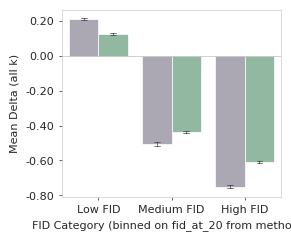

In [58]:
fig, ax = plot_delta_mean_bars_by_fid_bin(
    benzene_k_effect,
    method1='shap_sampling',
    method2='graph_mask',
    model='GIN',
    figsize=(3, 2.5),
    show_legend=False
)
fig.savefig("./benzene_k_effect_bar.svg", dpi=300)
plt.show()

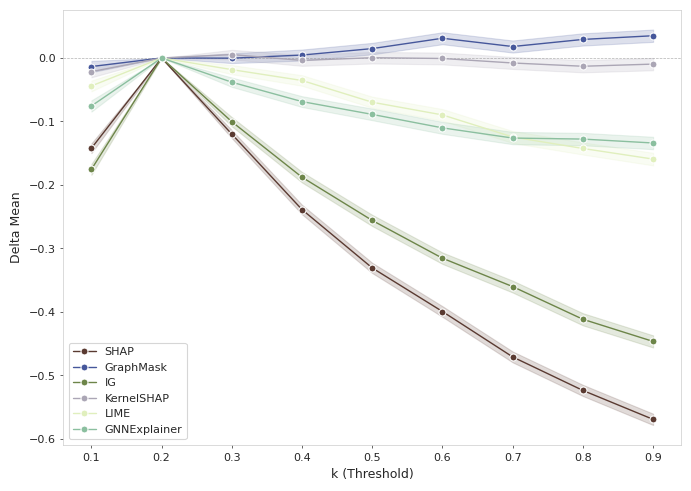

In [59]:
results = analyze_negative_deviation_k(
    df=benzene_k_effect,
    model='GIN',
    statistic='mean'
)

fig, ax = plot_negative_deviation_k_analysis(results, figsize=(7, 5))
fig.savefig("./negative_deviation_analysis_benzene.pdf", dpi=300)
plt.show()

In [66]:
delta_cols = [f'delta_{i/10:.1f}' for i in range(3, 10)]
for method in benzene_k_effect["explanation_method"].unique():
    print(f'method: {method}. mean delta: {benzene_k_effect[(benzene_k_effect["model"] == "GIN") & (benzene_k_effect["explanation_method"] == method)][delta_cols].mean(axis=1).mean()}')

method: grad_cam. mean delta: nan
method: guided_grad_cam. mean delta: nan
method: integrated_gradients. mean delta: -0.2968276778843826
method: kernel_shap. mean delta: -0.0042136175567643
method: lime. mean delta: -0.09136956296820303
method: shap_sampling. mean delta: -0.37896458239562597
method: gnn_explainer. mean delta: -0.09910067324130767
method: graph_mask. mean delta: 0.018907088841176305


### Conj System

In [60]:
conj_k_effect = compute_k_effect(conj_proc_df_all_thres, use_normalized_fid=True)

/tmp/ipykernel_1138912/52309927.py:69: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 0.5}` instead.

  sns.barplot(


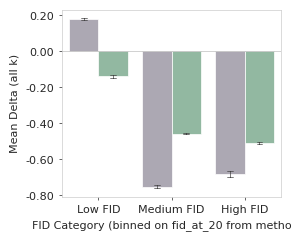

In [61]:
fig, ax = plot_delta_mean_bars_by_fid_bin(
    conj_k_effect,
    method1='shap_sampling',
    method2='graph_mask',
    model='GIN',
    figsize=(3, 2.5),
    show_legend=False
)
fig.savefig("./conj_k_effect_bar.svg", dpi=300)
plt.show()

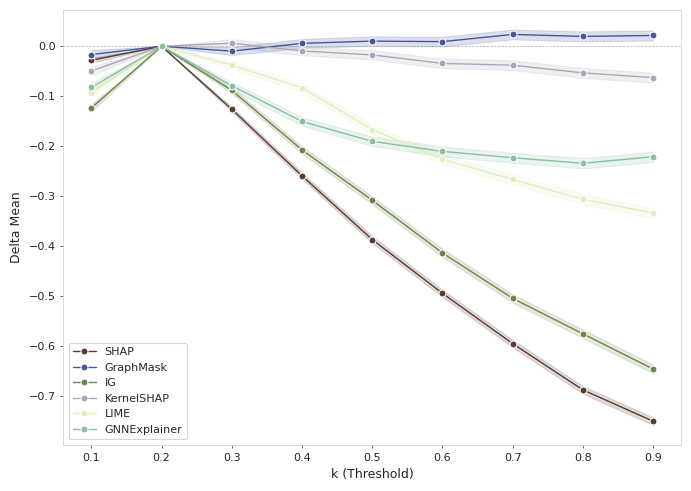

In [62]:
results = analyze_negative_deviation_k(
    df=conj_k_effect,
    model='GIN',
    statistic='mean'
)

fig, ax = plot_negative_deviation_k_analysis(results, figsize=(7, 5))
fig.savefig("./negative_deviation_analysis_conj.pdf", dpi=300)
plt.show()

In [31]:
delta_cols = [f'delta_{i/10:.1f}' for i in range(3, 10)]
for method in conj_k_effect["explanation_method"].unique():
    print(f'method: {method}. mean delta: {conj_k_effect[(conj_k_effect["model"] == "GIN") & (conj_k_effect["explanation_method"] == method)][delta_cols].mean(axis=1).mean()}')

method: grad_cam. mean delta: nan
method: guided_grad_cam. mean delta: nan
method: integrated_gradients. mean delta: -0.39181226115060175
method: kernel_shap. mean delta: -0.029864540403243933
method: lime. mean delta: -0.20279759817930446
method: shap_sampling. mean delta: -0.47124553076108544
method: gnn_explainer. mean delta: -0.186860219671559
method: graph_mask. mean delta: 0.011464210427436814


### Hbond donor

In [63]:
hbond_k_effect = compute_k_effect(hbond_proc_df_all_thres)

/tmp/ipykernel_1138912/52309927.py:69: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 0.5}` instead.

  sns.barplot(


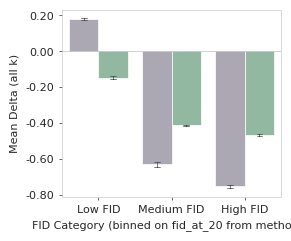

In [64]:
fig, ax = plot_delta_mean_bars_by_fid_bin(
    hbond_k_effect,
    method1='shap_sampling',
    method2='graph_mask',
    model='GIN',
    figsize=(3, 2.5),
    show_legend=False
)
fig.savefig("./hbond_k_effect_bar.svg", dpi=300)
plt.show()

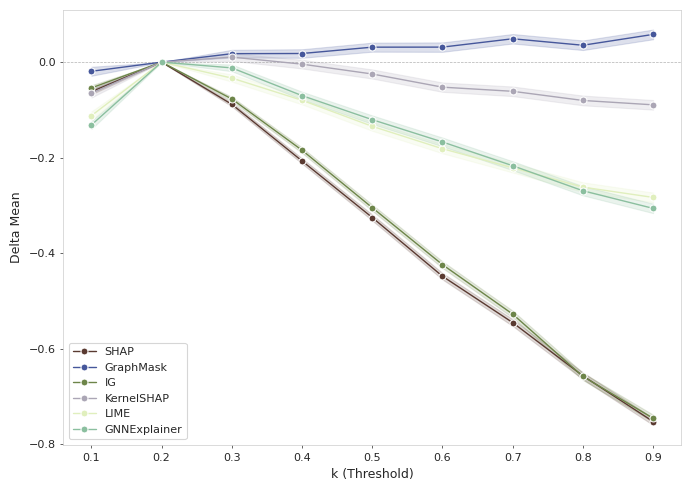

In [65]:
results = analyze_negative_deviation_k(
    df=hbond_k_effect,
    model='GIN',
    statistic='mean'
)

fig, ax = plot_negative_deviation_k_analysis(results, figsize=(7, 5))
fig.savefig("./negative_deviation_analysis_hbond.pdf", dpi=300)
plt.show()

In [32]:
delta_cols = [f'delta_{i/10:.1f}' for i in range(3, 10)]
for method in hbond_k_effect["explanation_method"].unique():
    print(f'method: {method}. mean delta: {hbond_k_effect[(hbond_k_effect["model"] == "GIN") & (hbond_k_effect["explanation_method"] == method)][delta_cols].mean(axis=1).mean()}')

method: grad_cam. mean delta: nan
method: guided_grad_cam. mean delta: nan
method: integrated_gradients. mean delta: -0.4175863746356207
method: kernel_shap. mean delta: -0.0431271877728967
method: lime. mean delta: -0.17083426805055257
method: shap_sampling. mean delta: -0.43216006153544423
method: gnn_explainer. mean delta: -0.16612402837141618
method: graph_mask. mean delta: 0.03440489128761488
